# Scaling Up: Network-Pruned Exact Solving

Robot beacon localization project — Step 7. Reuses `map_gen.py`, `visibility.py`, `solvers.py` and the trained network
from Step 6; the experiment itself is `dl_scale.py`.

`deep_learning.ipynb` ended on an open question. On the 16×12 training maps the exact pipeline is already fast, so the
network has no practical value there — but exact solving gets expensive as maps grow, while the network's forward pass
stays almost free. **Can the heatmap make the exact solver faster on larger maps?**

The idea is to **shrink the problem before solving it exactly**: keep only the candidates the network ranks highest, run
the usual constraint-generation solver over those, and add a pruned candidate back whenever some point needs it to reach
its requirement. The answer is always a valid, verified layout; the price is that it is optimal only over the kept
candidates.

The experiment covers 42 maps at three sizes — the 16×12 training size (the network's test maps) and maps with 2.25×
and 4× that area, which the network has never seen — and runs on every map:

| method | what it does |
|---|---|
| **exact** | constraint generation over all candidates — the reference optimum (two implementations, see Section 1) |
| **network top f** | the exact solver over the network's top fraction f of the candidates (f = 20%, 30%, 45%), with repair |
| **type rule top f** | the same, ranking candidates by type instead (pinch > reflex > midpoint > convex, rates from the training maps) — does the network beat a simple rule? |
| **hybrid decoding** | the network-guided greedy decoder of `deep_learning.ipynb` (no ILP) |

Times are wall-clock seconds from the finished map to a verified layout, including the network's forward pass. The
methods run in a random order on each map, so slow-downs during the long run favour none of them.

In [1]:
import os
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt

RESULTS = 'dl_scale.npz'
if not os.path.exists(RESULTS):                   # about 45 minutes; dl_scale.py can also be run and resumed separately
    subprocess.run([sys.executable, 'dl_scale.py', '--out', RESULTS], check=True)

R = list(np.load(RESULTS, allow_pickle=True)['results'])
SIZES = sorted({(r['w'], r['h']) for r in R}, key=lambda s: s[0] * s[1])
FRACS = (0.2, 0.3, 0.45)
maps = {s: [r for r in R if (r['w'], r['h']) == s] for s in SIZES}
label = {s: f'{s[0]}×{s[1]}' for s in SIZES}


def med(rs, method, key='t'):
    return float(np.median([r[method][key] for r in rs]))


print(f'{"map":>6} {"maps":>5} {"free cells":>11} {"candidates":>11} {"optimal beacons":>16}')
for s in SIZES:
    rs = maps[s]
    print(f'{label[s]:>6} {len(rs):>5} {np.mean([r["area"] for r in rs]):>11.0f} '
          f'{np.mean([r["n_cand"] for r in rs]):>11.0f} {np.mean([r["exact"]["n"] for r in rs]):>16.1f}')
print(f'\nlargest total ILP time in any reference (exact) run: {max(r["exact"]["ilp"] for r in R):.1f}s — below the 60 s '
      f'limit of a single CP-SAT solve, so every reference layout is a proven optimum')

   map  maps  free cells  candidates  optimal beacons
 16×12    20          82         133             24.2
 24×18    12         184         252             41.9
 32×24    10         336         394             57.5

largest total ILP time in any reference (exact) run: 35.7s — below the 60 s limit of a single CP-SAT solve, so every reference layout is a proven optimum


## 1. Where the exact solver spends its time

Profiling the exact solver on larger maps showed that most of its time went into **verification**: every
constraint-generation round recomputed the fine-grid visibility of *all* selected beacons, although consecutive
solutions share most of their beacons. Before pruning anything, `solvers.constraint_generation` was therefore changed to
(1) **cache** each beacon's fine-grid visibility across rounds and (2) **warm-start** every ILP from the previous
round's solution, which also cuts the number of rounds. The answer and its guarantee are unchanged; `reuse=False` still
runs the original implementation, compared below.

In [2]:
PARTS = ('init', 'ilp', 'verify', 'update')
print(f'{"map":>6}  {"solver":<9} {"time":>7}  | share of the time spent in')
print(f'{"":>6}  {"":<9} {"(s)":>7}  | {"setup":>7} {"ILP":>7} {"verify":>7} {"update":>7}')
print('-' * 66)
for s in SIZES:
    rs = maps[s]
    for m, name in [('exact_plain', 'original'), ('exact', 'cached')]:
        parts = np.array([[r[m][p] for p in PARTS] for r in rs]).sum(axis=0)
        print(f'{label[s] if m == "exact_plain" else "":>6}  {name:<9} {med(rs, m):>7.1f}  | '
              + ' '.join(f'{100 * v / parts.sum():>6.0f}%' for v in parts))
    speedup = np.median([r['exact_plain']['t'] / r['exact']['t'] for r in rs])
    iters = [np.mean([r[m]['iters'] for r in rs]) for m in ('exact_plain', 'exact')]
    print(f'{"":>6}  median speedup {speedup:.1f}x, iterations {iters[0]:.1f} → {iters[1]:.1f}')

   map  solver       time  | share of the time spent in
                      (s)  |   setup     ILP  verify  update
------------------------------------------------------------------
 16×12  original      0.9  |     26%     23%     49%      1%
        cached        0.7  |     40%     26%     32%      1%
        median speedup 1.3x, iterations 2.5 → 2.0
 24×18  original     13.3  |     17%     22%     60%      1%
        cached        6.8  |     33%     32%     34%      1%
        median speedup 1.7x, iterations 4.9 → 4.2
 32×24  original     54.1  |     16%     26%     58%      0%
        cached       29.7  |     32%     36%     31%      1%
        median speedup 1.9x, iterations 6.2 → 5.0


**The fix matters more the larger the map**: 1.3× faster on 16×12 maps and 1.9× on 32×24 maps (54 s → 30 s per map,
median). Verification falls from about 60% of the time to about a third, and the warm starts save half a round to a
full round of constraint generation per map. Setup (the initial visibility matrix) and the ILP now take two-thirds of
the time — exactly the two parts that pruning the candidates can shrink.

## 2. Time as the map grows

Median time per map for the exact solver (original and cached), for the exact solver over the top 45% of candidates
ranked by the network and by the type rule, and for hybrid decoding.

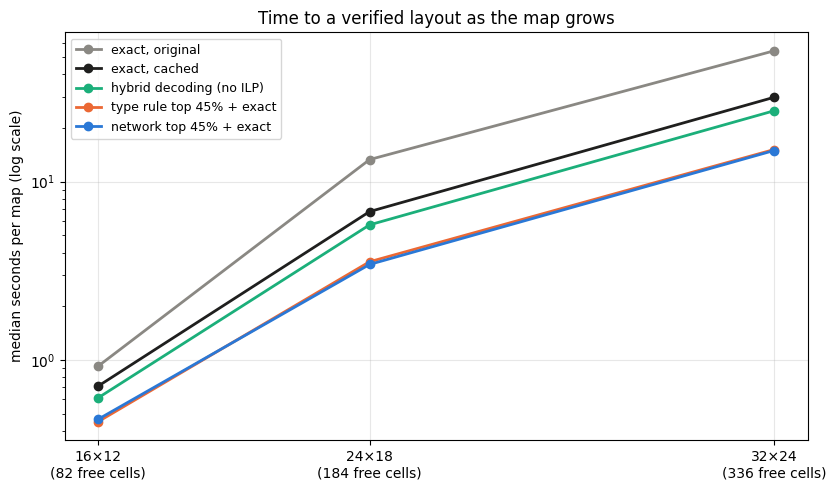

In [3]:
SERIES = [('exact_plain', 'exact, original', '#8a8883'), ('exact', 'exact, cached', '#1f1f1e'),
          ('hybrid', 'hybrid decoding (no ILP)', '#1baf7a'), ('prior_0.45', 'type rule top 45% + exact', '#eb6834'),
          ('nn_0.45', 'network top 45% + exact', '#2a78d6')]
area = [np.mean([r['area'] for r in maps[s]]) for s in SIZES]

fig, ax = plt.subplots(figsize=(8.5, 5))
for key, name, col in SERIES:
    ax.plot(area, [med(maps[s], key) for s in SIZES], 'o-', color=col, linewidth=2, markersize=6, label=name)
ax.set_yscale('log')
ax.set_xticks(area)
ax.set_xticklabels([f'{label[s]}\n({a:.0f} free cells)' for s, a in zip(SIZES, area)])
ax.set_ylabel('median seconds per map (log scale)')
ax.set_title('Time to a verified layout as the map grows')
ax.grid(alpha=0.3); ax.set_axisbelow(True); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Doubling the side of the map makes exact solving about 40× slower (0.7 s → 30 s with the cached solver). Pruning to the
network's top 45% halves that on 32×24 maps (15 s), and its advantage grows with the map: 1.55× → 1.69× → 1.94× over
the cached exact solver, and 2.0× → 3.1× → 4.2× over the original one. Hybrid decoding needs the same visibility
computations without the ILP, so it is barely faster than exact solving — and, as the next section shows, much worse.

## 3. Speed vs. extra beacons

For each size: how many beacons each method uses beyond the exact optimum, how often it hits the optimum exactly, and
its median speedup over the (cached) exact solver. In the chart, each curve runs from keeping 20% of the candidates
(fastest, most extra beacons) to keeping 45%; the ideal corner is the top left.


16×12: 20 maps, 24.2 beacons in the exact solution
method                extra  extra %  optimal    time  speedup
--------------------------------------------------------------
exact (cached)        +0.00    +0.0%     100%    0.7s    1.00x
network top 20%       +1.90    +8.0%      20%    0.3s    1.98x
network top 30%       +1.10    +4.7%      30%    0.4s    1.98x
network top 45%       +0.35    +1.6%      70%    0.5s    1.55x
type rule top 20%     +1.80    +7.9%      15%    0.3s    1.87x
type rule top 30%     +1.15    +5.1%      25%    0.4s    1.76x
type rule top 45%     +0.85    +3.7%      35%    0.5s    1.58x
hybrid decoding       +1.55    +6.6%      15%    0.6s    1.12x
network top 45% vs the original exact solver: 2.0x faster (median)

24×18: 12 maps, 41.9 beacons in the exact solution
method                extra  extra %  optimal    time  speedup
--------------------------------------------------------------
exact (cached)        +0.00    +0.0%     100%    6.8s    1.00x
network to

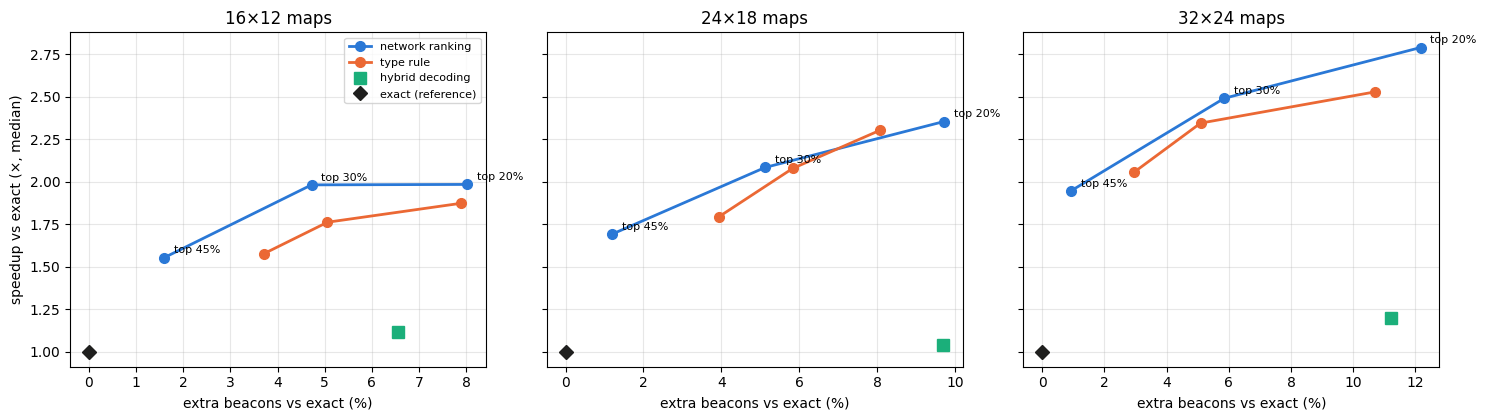

In [4]:
METHODS = ['exact'] + [f'nn_{f}' for f in FRACS] + [f'prior_{f}' for f in FRACS] + ['hybrid']
NAME = {'exact': 'exact (cached)', 'hybrid': 'hybrid decoding',
        **{f'nn_{f}': f'network top {100 * f:.0f}%' for f in FRACS},
        **{f'prior_{f}': f'type rule top {100 * f:.0f}%' for f in FRACS}}


def stats(rs, m):
    """mean extra beacons, mean extra %, share of maps at the optimum, median time, median speedup vs exact"""
    extra = np.array([r[m]['n'] - r['exact']['n'] for r in rs])
    rel = np.array([100 * (r[m]['n'] - r['exact']['n']) / r['exact']['n'] for r in rs])
    speedup = np.array([r['exact']['t'] / r[m]['t'] for r in rs])
    return extra.mean(), rel.mean(), 100 * (extra == 0).mean(), med(rs, m), np.median(speedup)


for s in SIZES:
    print(f'\n{label[s]}: {len(maps[s])} maps, {np.mean([r["exact"]["n"] for r in maps[s]]):.1f} beacons in the exact solution')
    print(f'{"method":<20} {"extra":>6} {"extra %":>8} {"optimal":>8} {"time":>7} {"speedup":>8}')
    print('-' * 62)
    for m in METHODS:
        e, rel, opt, t, sp = stats(maps[s], m)
        print(f'{NAME[m]:<20} {e:>+6.2f} {rel:>+7.1f}% {opt:>7.0f}% {t:>6.1f}s {sp:>7.2f}x')
    comb = np.median([r['exact_plain']['t'] / r['nn_0.45']['t'] for r in maps[s]])
    print(f'network top 45% vs the original exact solver: {comb:.1f}x faster (median)')

fig, axes = plt.subplots(1, len(SIZES), figsize=(5 * len(SIZES), 4.3), sharey=True, squeeze=False)
for ax, s in zip(axes[0], SIZES):
    for rank, col, name in [('nn', '#2a78d6', 'network ranking'), ('prior', '#eb6834', 'type rule')]:
        pts = [stats(maps[s], f'{rank}_{f}') for f in FRACS]
        ax.plot([p[1] for p in pts], [p[4] for p in pts], 'o-', color=col, linewidth=2, markersize=7, label=name)
        if rank == 'nn':
            for f, p in zip(FRACS, pts):
                ax.annotate(f'top {100 * f:.0f}%', (p[1], p[4]), textcoords='offset points', xytext=(7, 3), fontsize=8)
    hy = stats(maps[s], 'hybrid')
    ax.plot(hy[1], hy[4], 's', color='#1baf7a', markersize=8, label='hybrid decoding')
    ax.plot(0, 1, 'D', color='#1f1f1e', markersize=7, label='exact (reference)')
    ax.set_title(f'{label[s]} maps')
    ax.set_xlabel('extra beacons vs exact (%)')
    ax.grid(alpha=0.3); ax.set_axisbelow(True)
axes[0, 0].set_ylabel('speedup vs exact (×, median)')
axes[0, 0].legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

**Keeping the top 45% is the sweet spot.** It costs about 1% extra beacons — never more than 2 per map, and at most 1
on the 32×24 maps — finds the exact optimum on 50–70% of the maps, and is 1.6–1.9× faster than the cached exact solver.
Pruning harder buys only a little more speed (up to 2.8×) for 5–12% extra beacons.

**The network beats the simple rule where it matters.** At the 45% cutoff the type rule needs 2–3× as many extra
beacons and finds the optimum on only 10–35% of the maps. At 20–30% the two are about even — the rule is even slightly
ahead at 20% on the larger maps — so the network's edge lies in telling which candidates are safe to drop, not in
naming a tiny core.

**Hybrid decoding is dominated**: on the larger maps it is barely faster than exact solving (1.04–1.2×), yet uses
about 10% more beacons and never finds the optimum.

## 4. Does the network still rank well on larger maps?

The network never saw a map larger than 16×12. Two measures of its ranking against the exact solution on each map:
the AUC (can it rank the solution's beacons ahead of the rest), and the share of the solution's beacons that survive
each pruning cutoff — a beacon pruned away can only come back through the repair step.

In [5]:
print(f'{"map":>6} | {"AUC":>7} {"AUC":>9} | share of the exact solution inside the top 20% / 30% / 45%')
print(f'{"":>6} | {"network":>7} {"type rule":>9} | {"network":>18}   {"type rule":>18}')
print('-' * 72)
for s in SIZES:
    rs = maps[s]
    rec = {k: ' / '.join(f'{100 * np.mean([r[f"recall_{k}"][f] for r in rs]):.0f}%' for f in FRACS) for k in ('nn', 'prior')}
    print(f'{label[s]:>6} | {np.mean([r["auc_nn"] for r in rs]):>7.3f} {np.mean([r["auc_prior"] for r in rs]):>9.3f} | '
          f'{rec["nn"]:>18}   {rec["prior"]:>18}')

print('\ncandidates added back by the repair step (mean per map), cutoff 20% / 30% / 45%')
for s in SIZES:
    rep = {k: ' / '.join(f'{np.mean([r[f"{k}_{f}"]["kept"] - round(f * r["n_cand"]) for r in maps[s]]):.1f}' for f in FRACS)
           for k in ('nn', 'prior')}
    print(f'{label[s]:>6} | network {rep["nn"]:<16} type rule {rep["prior"]}')

   map |     AUC       AUC | share of the exact solution inside the top 20% / 30% / 45%
       | network type rule |            network            type rule
------------------------------------------------------------------------
 16×12 |   0.865     0.748 |    59% / 76% / 90%      48% / 67% / 75%
 24×18 |   0.834     0.733 |    55% / 74% / 86%      40% / 62% / 76%
 32×24 |   0.848     0.747 |    61% / 75% / 89%      45% / 65% / 78%

candidates added back by the repair step (mean per map), cutoff 20% / 30% / 45%
 16×12 | network 5.4 / 0.8 / 0.0  type rule 8.5 / 3.5 / 1.1
 24×18 | network 10.0 / 2.2 / 0.3 type rule 17.1 / 8.3 / 2.8
 32×24 | network 9.1 / 1.2 / 0.0  type rule 22.3 / 10.0 / 2.8


**The network's ranking carries over to maps it has never seen.** Its AUC stays at 0.83–0.87 up to 4× the training
area (type rule: about 0.75), and its top 45% holds 86–90% of the exact solution's beacons (type rule: 75–78%). That is
why the repair step almost never has to add a candidate back at the 45% cutoff, and why the pruned answer is usually
the optimum or one beacon off.

## Summary

**On larger maps the network pays off — as a pruning prior for the exact solver, not as a replacement for it.**

- **Engineering first.** Caching verification results and warm-starting the ILP make the exact solver 1.3–1.9×
  faster, more on larger maps, with the same guarantee.
- **Network pruning on top.** Solving exactly over the network's top 45% of candidates is another 1.6–1.9× faster for
  about 1% more beacons (at most 2 per map), and finds the optimum on 50–70% of the maps. On 32×24 maps the two
  together cut the median time from 54 s to 15 s.
- **Better than a simple rule, and it generalizes.** Ranking candidates by type costs 2–3× as many extra beacons at
  the same cutoff; the network's ranking (AUC ≈ 0.85) holds up on maps 4× larger than any it was trained on.
- **Hybrid decoding is not the way to use the network at scale**: barely faster than exact solving, and about 10% worse.

**Limitations and next steps**:

- 42 maps up to 4× the training area, one run per method and map, timed on one laptop; medians and per-map ratios damp
  the noise but do not remove it.
- A pruned answer is optimal only over the kept candidates — it carries no lower bound, so the full exact solver is
  still needed when a proven optimum matters.
- Verification is now the largest cost that pruning cannot touch; a faster visibility kernel would speed up every method.
- The network has only seen 16×12 maps. The pruned solver makes verified labels on large maps much cheaper to produce,
  so training on larger maps — and pushing to larger sizes — is the natural next step.